# setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import sys
import copy
import json
import inspect
sys.path.append(r'src')
from tqdm.notebook import tqdm

import random
from datetime import date, datetime
from pathlib import Path
import pandas as pd
import os
import time
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

from src.game_arena import base
from src.game_arena import utils
from src.game_arena import run_leaderboard

from experimental.exp_utils import model_name_map, get_logo, Image, get_main_elo_data, get_match_results, get_match_file_path, get_done_count, MODEL_NAME_MAP, MAIN_GAMES_WORLD_COLUMNS, NAME_DELETE, NAME_FIX_MAP
from experimental.lm_arena.rating_systems import compute_bt
from experimental.lm_arena.simple_example import _build_battles, main_results
from experimental.lm_arena import simple_example


# Chess UCI vs Chess

chess world1 85150
chess worlduci1 18300
LEGACY {'name0': 'qwen3_235b_a22b_2507/003', 'name1': 'minimax_m2.1/003', 'winner': 'timeout', 'done': False, 'r': None, 'exception': 'Game execution exceeded timeout of 20 seconds', 'exception_traceback': 'Traceback (most recent call last):\n  File "/storage/ANON/projects/synthesis/arena/CA_arena/src/game_arena/base.py", line 201, in play_game_with_timeout\n    raise TimeoutError(f"Game execution exceeded timeout of {timeout} seconds")\nTimeoutError: Game execution exceeded timeout of 20 seconds\n', 'time_analysis': {'1': 11.810721635818481, '0': 0.15936517715454102, 'last': ['1', 8.155824899673462]}, 'now': 20.159818172454834}
LEGACY {'name0': 'qwen3_235b_a22b_2507/003', 'name1': 'minimax_m2.1/003', 'winner': 'timeout', 'done': False, 'r': None, 'exception': 'Game execution exceeded timeout of 20 seconds', 'exception_traceback': 'Traceback (most recent call last):\n  File "/storage/ANON/projects/synthesis/arena/CA_arena/src/game_arena/base.py"

/tmp/ipykernel_2970772/3603027343.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


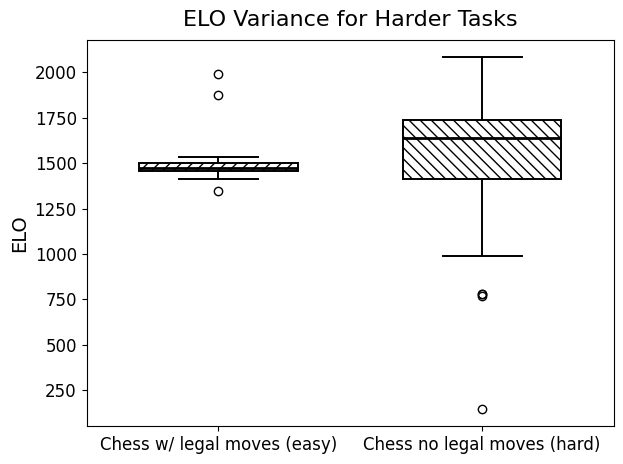

In [3]:
import matplotlib.pyplot as plt

gs = [('chess', 'world1', 'Chess', None), ('chess', 'worlduci1', 'Chess UCI', None)]
main_elo_data = get_main_elo_data(gs, result_dir='results_side_experiments/results_chess_uci_vs_normal')
elos = main_elo_data['elos']
colnames = main_elo_data['colnames']

with plt.rc_context({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
}):
    # ---- everything in here uses the custom fonts ----
    fig, ax = plt.subplots()

    data = [elos[0]['ELO'].dropna().values, elos[1]['ELO'].dropna().values]
    labels = {"Chess": "Chess w/ legal moves (easy)", "Chess UCI": "Chess no legal moves (hard)"}
    labels = [labels[col] for col in colnames]


    bp = ax.boxplot(
        data,
        labels=labels,
        patch_artist=True,
        widths=0.6,
        showfliers=True
    )

    hatches = ["///", "\\\\\\"]
    for patch, hatch in zip(bp["boxes"], hatches):
        patch.set_facecolor("none")
        patch.set_edgecolor("black")
        patch.set_linewidth(1.4)
        patch.set_hatch(hatch)

    for median in bp["medians"]:
        median.set_color("black")
        median.set_linewidth(2.0)

    for whisker in bp["whiskers"]:
        whisker.set_color("black")
        whisker.set_linewidth(1.4)

    for cap in bp["caps"]:
        cap.set_color("black")
        cap.set_linewidth(1.4)

    for flier in bp["fliers"]:
        flier.set_marker("o")
        flier.set_markerfacecolor("none")
        flier.set_markeredgecolor("black")
        flier.set_markersize(6)

    ax.set_title("ELO Variance for Harder Tasks", pad=10)
    ax.set_ylabel("ELO")

    plt.tight_layout()
    plt.show()

# -------- Save to SVG --------
out_pdf = "figures/elo_variance_san_vs_uci.pdf"
fig.savefig(out_pdf, format="pdf", bbox_inches="tight")
plt.show()


# Memory vs No Memory

## Generate combined world

In [ ]:
game_str = 'go'
# game_str = 'chess'
world_no_mem = 'world1'
# world_no_mem = 'worlduci1'
world_mem = 'worldmem1'
# world_mem = 'worlducimem1'

all_data_pruned = get_match_results(get_match_file_path(game_str, world_no_mem))
_, top_models_nomem = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)

all_data_pruned = get_match_results(get_match_file_path(game_str, world_mem))
_, top_models_mem = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)


ERROR========================== go worldmem1
ERROR go worldmem1: Multiple matches found for go worldmem1: [PosixPath('results_side_experiments/results_memory/matches_go_worldmem1_2016_1.json'), PosixPath('results_side_experiments/results_memory/matches_go_worldmem1_2016_1_old.json'), PosixPath('results_side_experiments/results_memory/matches_go_worldmem1_2211_1.json')]


AssertionError: Match JSON file not found None

In [76]:
limit_model_bots = 5
n_games = 1
timeout = 20
max_workers = 32

config = utils.get_config_file(game_str, world_no_mem)
all_bots = []

bots = list(utils.get_bot_paths_from_world(game_str, world_no_mem, add_random=True, allowed_bot_nums='0,1,2,3,4').items())
print('world1 pre filter', len(bots))
bots = [b for b in bots if b[0] in top_models_nomem]
bots = [(f'nomem:{bot_name}', policy) for bot_name, policy in bots]
print('world1 post filter', len(bots))
all_bots.extend(bots)

bots = list(utils.get_bot_paths_from_world(game_str, world_mem, add_random=True, allowed_bot_nums='0,1,2,3,4').items())
print('worldmem1 pre filter', len(bots))
bots = [b for b in bots if b[0] in top_models_mem or b[0].startswith('deepseek_v3.2_speciale')]
bots = [(f'mem:{bot_name}', policy) for bot_name, policy in bots]
print('worldmem1 post filter', len(bots))
all_bots.extend(bots)


todo = []
for i, p1 in enumerate(all_bots):
    for p2 in all_bots[i+1:]:
        todo.append((p1, p2))
print('len todo', len(todo))
assert len(todo) > 0, 'No games to play. Exiting.'


world1 pre filter 157
world1 post filter 29
worldmem1 pre filter 159


NameError: name 'top_models_mem' is not defined

In [ ]:
game = utils.get_game(game_str)
def game_creator():
    return game(config)
game_creator.__name__ = game.__name__

final_result_path = utils.get_root_path() / 'results_memory' / f'matches_{game_str}_{world_mem}_{len(todo)}_{n_games}.json'
print(f'game = {game_str}, world = {world_mem}, len(todo) = {len(todo)}')
result = base.play_all_2p_games(game_creator, todo, n_games=n_games, timeout=timeout, verbose=False, max_workers=max_workers)

final_result_path.parent.mkdir(parents=True, exist_ok=True)
with open(final_result_path, 'w') as f:
    json.dump(result, f, indent=2)


In [ ]:
final_result_path.parent.mkdir(parents=True, exist_ok=True)
with open(final_result_path, 'w') as f:
    json.dump(result, f, indent=2)


## Plot

In [170]:
gs = [
    ['go', 'worldmem1', Path('results_side_experiments/results_memory/matches_go_worldmem1_2211_1.json'), 'Go Comparison'],
    ['chess', 'worlducimem1', Path('results_side_experiments/results_memory/matches_chess_worlducimem1_1891_1.json'), 'Chess UCI Comparison'],
 
    # ['chess', 'worldmem1', Path('results_side_experiments/results_memory/matches_chess_worldmem1_1953_1.json'), 'Chess Comparison'],
    # ['go', 'world1', None, 'Go'],
    # ['go', 'worldmem1', None, 'Go W/Memory'],
    # ['go', 'worldmem1', Path('results_side_experiments/results_memory/matches_go_worldmem1_2016_1.json'), 'Go Comparison'],
]

elos_mem = []
elos_mem_colnames = []
elos_mem_done_count = {}
elos_mem_raw_match_data = {}
elos_mem_top_bots = {}
total_num_games = 0
NAME_FIX = {
    'mem:random': 'random',
    'nomem:random': 'random',
}
for game_str, world, match_json, colname in gs:
    all_data_pruned = get_match_results(match_json)
    elos_mem_raw_match_data[colname] = copy.deepcopy(all_data_pruned)
    # elos_mem_raw_match_data[colname] = all_data_pruned
    num_games = len(all_data_pruned)
    print(f'{game_str} {world} {len(all_data_pruned)}')
    total_num_games += num_games

    elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False, learning_rate=4, iters=500)
    elos_mem_top_bots[colname] = top_models
    top_models_names = set(top_models)
    all_data_pruned = [g for g in all_data_pruned if g['name0'] in top_models_names and g['name1'] in top_models_names]
    for g in all_data_pruned:
        g['name0'] = g['name0'].split('/')[0]
        g['name1'] = g['name1'].split('/')[0]
        g['name0'] = NAME_FIX.get(g['name0'], g['name0'])
        g['name1'] = NAME_FIX.get(g['name1'], g['name1'])
    elo_post, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False, learning_rate=4, iters=500)
    if 'Comparison' not in colname:
        elos_mem.append(elo_post)
        elos_mem_colnames.append(colname)
    else:
        # need to split into two columns
        nomem_df = elo_post[elo_post.index.str.startswith('nomem:')].rename(index=lambda x: x.replace('nomem:', '', 1))
        nomem_df.loc['random'] = elo_post.loc['random']
        mem_df   = elo_post[elo_post.index.str.startswith('mem:')].rename(index=lambda x: x.replace('mem:', '', 1))
        mem_df.loc['random'] = elo_post.loc['random']
        elos_mem.append(nomem_df)
        elos_mem.append(mem_df)
        elos_mem_colnames.append(colname + ' No Memory')
        elos_mem_colnames.append(colname + ' With Memory')

    elos_mem_done_count[colname] = get_done_count(all_data_pruned)

print('total games =', total_num_games)
for i in range(len(elos_mem)):
    elos_mem[i] = elos_mem[i].astype(float)
elos_mem_df = pd.concat(elos_mem, axis=1)
elos_mem_df.columns = elos_mem_colnames
elos_mem_df = elos_mem_df[(elos_mem_df.index != 'gpt_5.2_pro') & (elos_mem_df.index != 'deepseek_v3.2_speciale')]
# elos_mem_df = elos_mem_df[(elos_mem_df.index != 'gpt_5.2_pro')]
elos_mem_top_bots

go worldmem1 4422
chess worlducimem1 3782
total games = 8204


{'Go Comparison': Index(['mem:claude_opus_4.5/003', 'mem:claude_sonnet_4.5/003',
        'mem:deepseek_chat_v3_0324/004', 'mem:deepseek_r1t2_chimera_free/001',
        'mem:deepseek_v3.2/001', 'mem:deepseek_v3.2_speciale/001',
        'mem:devstral_2512_free/003', 'mem:gemini_2.0_flash_001/005',
        'mem:gemini_3_flash_preview/005', 'mem:gemini_3_pro_preview/004',
        'mem:glm_4.7/002', 'mem:gpt_4o_mini/001', 'mem:gpt_5.2/005',
        'mem:gpt_5.2_codex/001', 'mem:gpt_5_mini/005', 'mem:gpt_oss_120b/003',
        'mem:grok_code_fast_1/003', 'mem:kat_coder_pro/001',
        'mem:kimi_k2_thinking/001', 'mem:mimo_v2_flash_free/003',
        'mem:minimax_m2/002', 'mem:minimax_m2.1/005',
        'mem:ministral_14b_2512/004', 'mem:nemotron_nano_12b_v2_vl_free/002',
        'mem:qwen3_235b_a22b_2507/005', 'mem:qwen3_32b/002',
        'mem:qwen3_coder/001', 'mem:qwen3_coder_30b_a3b_instruct/003',
        'mem:qwen3_next_80b_a3b_instruct/003', 'mem:random',
        'mem:tng_r1t_chimera_

In [171]:
# ms = [m for m in elos_mem_raw_match_data['Go Comparison'] if m['name0'].startswith('mem:deepseek_v3.2_speciale') or m['name1'].startswith('mem:deepseek_v3.2_speciale')]
ms = [m for m in elos_mem_raw_match_data['Go Comparison'] if m['name0'] == 'mem:deepseek_v3.2_speciale' or m['name1'] == 'mem:deepseek_v3.2_speciale']
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(pd.DataFrame(ms))


""


In [172]:
print('WIN/LOSS/DRAW/ERROR/TIMEOUT breakdown for a game:')
colname = 'Go Comparison'
all_scores_df = run_leaderboard.get_scores_from_match_data(elos_mem_raw_match_data[colname])
all_scores_df['total'] = all_scores_df.sum(1)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(all_scores_df.loc[all_scores_df.index.str.contains('gpt_5.2_codex/') | all_scores_df.index.str.contains('qwen3_coder_30b_a3b_instruct')].sort_values('win', ascending=False))
    # display(all_scores_df.loc[all_scores_df.index.str.contains('gemini')].sort_values('win', ascending=False))


WIN/LOSS/DRAW/ERROR/TIMEOUT breakdown for a game:


/tmp/ipykernel_461204/2339984147.py:4: Pandas4Warning:

Starting with pandas version 4.0 all arguments of sum will be keyword-only.



,win,loss,draw,error,timeout,enemy_error,enemy_timeout,total
mem:qwen3_coder_30b_a3b_instruct/003,52,3,2,0,12,28,35,132
mem:gpt_5.2_codex/001,28,15,1,11,10,38,29,132
nomem:gpt_5.2_codex/002,23,14,0,1,0,30,64,132
nomem:qwen3_coder_30b_a3b_instruct/004,7,3,0,100,0,16,6,132


In [173]:
elos_mem_df

,Go Comparison No Memory,Go Comparison With Memory,Chess UCI Comparison No Memory,Chess UCI Comparison With Memory
gpt_5.2_codex,1963.05,1718.85,1782.82,1640.23
kimi_k2_thinking,1861.05,1464.40,1778.22,2054.42
gpt_5_mini,1763.23,1857.76,2023.36,2056.82
gpt_5.2,1746.07,2017.44,2083.87,1879.63
gemini_3_pro_preview,1732.45,1778.34,1855.92,1747.15
gpt_oss_120b,1697.97,1695.86,1584.67,1668.33
qwen3_32b,1680.50,1590.00,1557.67,1614.55
minimax_m2,1672.32,1706.50,1351.15,1803.68
kat_coder_pro,1643.92,1257.48,1369.48,1287.83
tng_r1t_chimera_free,1608.12,1665.22,1630.83,1478.26


With Memory = 1543.4, No Memory = 1464.7


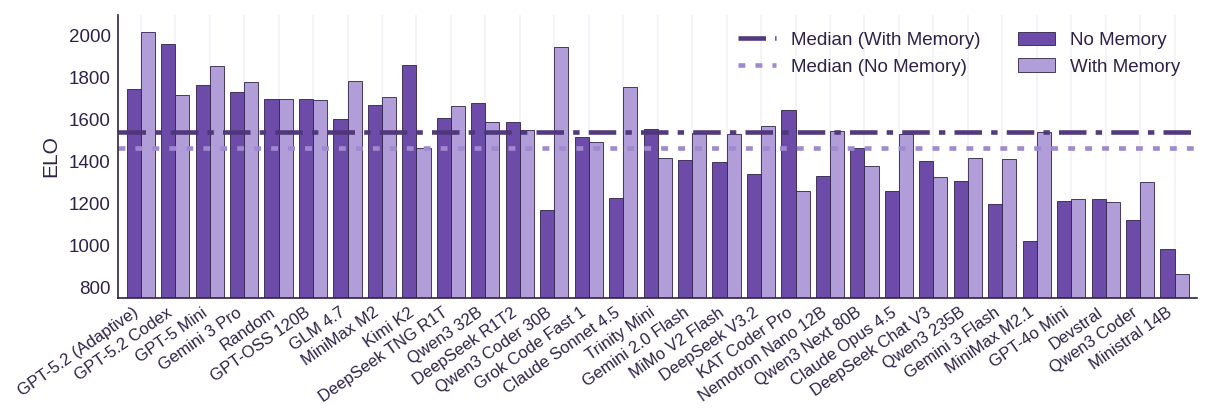

With Memory = 1629.4, No Memory = 1606.7


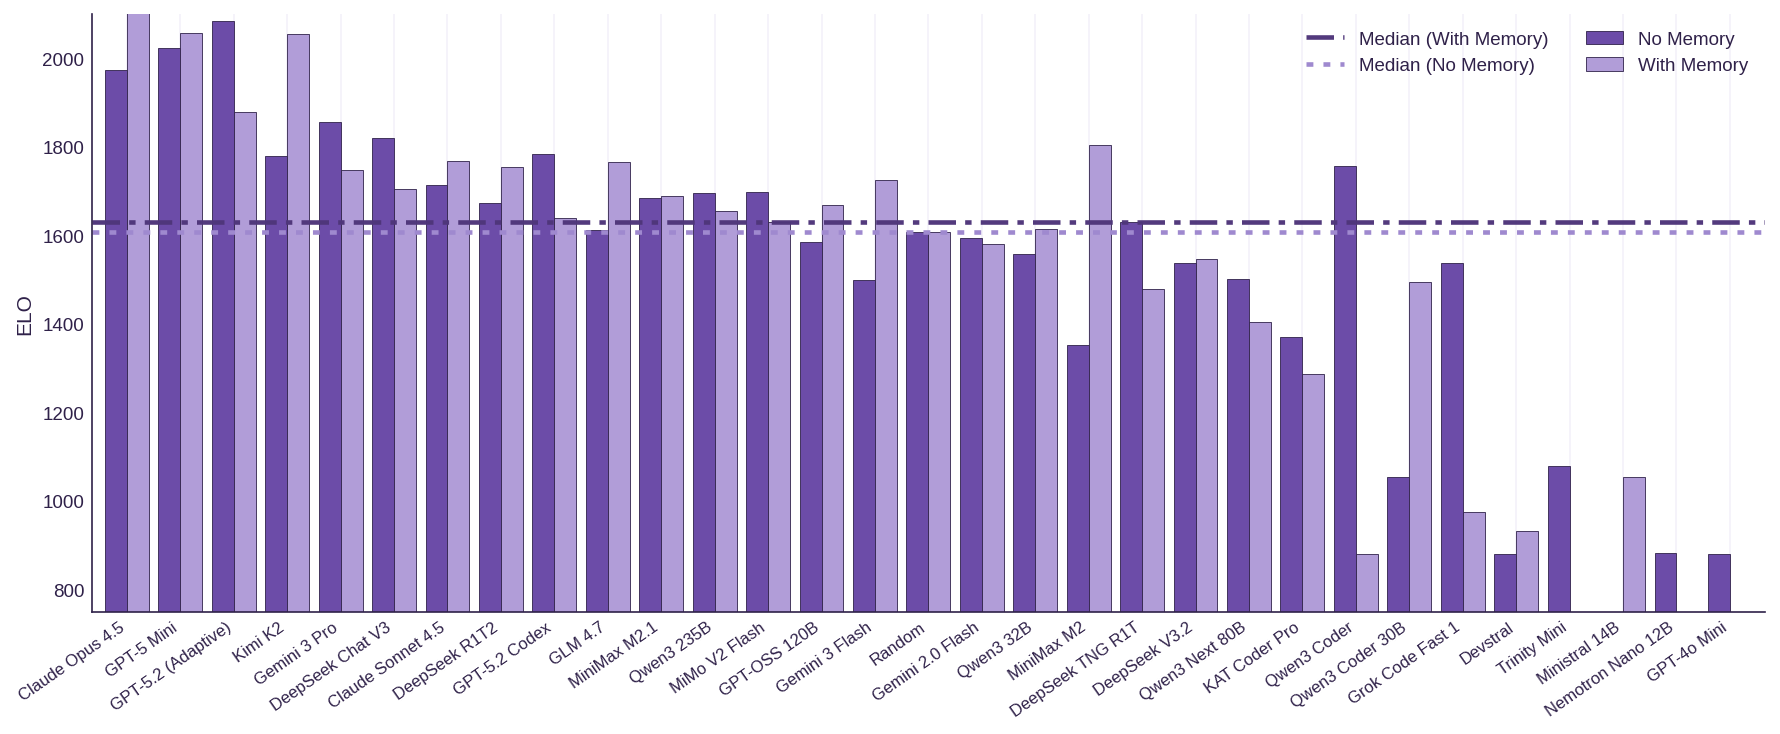

In [176]:
from temp_mem_plot import mem_plot

# game_str = 'Chess'
# title = f'Chess SAN (with legal moves) Automata Comparison'
game_str = 'Go'
title = f'Go Automata Comparison'
mem_plot(game_str, title, elos_mem_df, model_name_map, figsize=(8.2, 2.9))

game_str = 'Chess UCI'
title = f'Chess Automata Comparison'
mem_plot(game_str, title, elos_mem_df, model_name_map, figsize=(12, 5))


# live play ELO

In [3]:
def patch_llm_name(m, prefix: str):
    if m['name0'].startswith('LLM_'):
        m['name0'] = 'LLM_' + prefix + m['name0'][4:]
    elif m['name1'].startswith('LLM_'):
        m['name1'] = 'LLM_' + prefix + m['name1'][4:]
    else:
        raise ValueError(f"Invalid name: {m['name0']} or {m['name1']}")
    return m

d = Path('./results_side_experiments/results_live')
results = {}
for model_name in d.iterdir():
    if not model_name.is_dir() or model_name.name == 'trash':
        continue
    counts = {f.name: len(list(f.glob('**/*.json'))) for f in model_name.iterdir()}
    print(model_name, counts)
    for f in model_name.glob('**/*.json'):
        try:
            with open(f, 'r') as fd:
                data = json.load(fd)
        except Exception as e:
            print(f'Error loading {f}: {e}')
            continue
        game_world = f.parent.name
        game, world = game_world.rsplit('_', 1)
        if (game, world) not in results:
            results[(game, world)] = {}
        if model_name.name not in results[(game, world)]:
            results[(game, world)][model_name.name] = []
        data['r'] = {'player_err_counts': data['player_err_counts']}
        show_legal_moves = data.get('live_play', {}).get('show_legal_moves', False)
        if show_legal_moves:
            patch_llm_name(data, 'PEEK_')
        if not data['done']:
            continue
        results[(game, world)][model_name.name].append(data)

match_results = {}
match_results_vs_bot = {}
for game, world in results:
    for model_name, data in results[(game, world)].items():
        if (game, world) not in match_results:
            match_results[(game, world)] = {}
            match_results_vs_bot[(game, world)] = {}
        match_results[(game, world)][model_name] = {
            'winner_LLM': 0,
            'winner_Automata': 0,
            'draw': 0,
            'err_LLM': 0,
            'err_Automata': 0,
        }
        match_results_vs_bot[(game, world)][model_name] = {}
        for m in data:
            res = run_leaderboard.get_match_result(m, False)
            if res[0] == 'win':
                winner = 'LLM' if m[f'name{res[1]}'].startswith('LLM') else 'Automata'
                match_results[(game, world)][model_name]['winner_' + winner] += 1
                bot_name = m[f'name0'] if m[f'name1'].startswith('LLM') else m[f'name1']
                if bot_name not in match_results_vs_bot[(game, world)][model_name]:
                    match_results_vs_bot[(game, world)][model_name][bot_name] = {'win': 0, 'lose': 0}
                match_results_vs_bot[(game, world)][model_name][bot_name]['win' if winner == 'LLM' else 'lose'] += 1
            elif res[0] == 'draw':
                match_results[(game, world)][model_name]['draw'] += 1
            elif 1 in m['player_err_counts']:
                err_idx = m['player_err_counts'].index(1)
                err = 'LLM' if m[f'name{err_idx}'].startswith('LLM') else 'Automata'
                match_results[(game, world)][model_name]['err_' + err] += 1
                # if err == 'LLM':
                #     print(m['exception'])
            else:
                raise ValueError(f"Invalid match result: {m}")
for g, data in match_results.items():
    print('Game:', g[0])
    for model_name, data in data.items():
        print('   LLM:', model_name, 'Results =', data)
print('--------------------------------')
print('Breakdown by opponent:')
for g, data in match_results_vs_bot.items():
    print(g[0])
    for llm_name, data in data.items():
        print('   LLM:', llm_name, end='')
        for bot_name, data in data.items():
            print(' ', bot_name, data, end='')
        print('|END OF RESULTS|')


results_side_experiments/results_live/qwen3_coder {'connect4_world1': 10, 'chess_worlduci1': 25}
results_side_experiments/results_live/kat_coder_pro {'connect4_world1': 10, 'chess_worlduci1': 25}
results_side_experiments/results_live/grok_code_fast_1 {'chess_worlduci1': 22}
results_side_experiments/results_live/minimax_m2 {'connect4_world1': 10, 'chess_worlduci1': 16}
results_side_experiments/results_live/trinity_mini_free {'connect4_world1': 104}
results_side_experiments/results_live/deepseek_v3.2 {'connect4_world1': 10, 'chess_worlduci1': 25}
results_side_experiments/results_live/gemini_2.0_flash_001 {'connect4_world1': 10, 'chess_worlduci1': 25}
results_side_experiments/results_live/tng_r1t_chimera_free {'connect4_world1': 92}
results_side_experiments/results_live/devstral_2512_free {'dots_and_boxes_world1': 34, 'clobber_world1': 22, 'hex_world1': 34, 'chess_world1': 43, 'breakthrough_world1': 17, 'connect4_world1': 22}
results_side_experiments/results_live/gemini_3_flash_preview {'

In [4]:
gs = [
    # ['hex', 'world1', None, 'Hex'],
    # ['dots_and_boxes', 'world1', None, 'Dots and Boxes'],
    # ['clobber', 'world1', None, 'Clobber'],
    # ['breakthrough', 'world1', None, 'Breakthrough'],
    # ['chess', 'world1', None, 'Chess'],
    ['connect4', 'world1', None, 'Connect4'],
    ['chess', 'worlduci1', None, 'Chess UCI'],
]

live_play_elos = []
live_play_data = []
for game_str, world, match_json, colname in gs:
    if match_json is None:
        match_json = get_match_file_path(game_str, world, result_dir='results_current/results_somerset_feb_20/tourney')
    all_data_pruned = get_match_results(match_json)
    assert isinstance(all_data_pruned, list)

    elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)
    if (game_str, world) in results:
        for model_name, data in results[(game_str, world)].items():
            all_data_pruned.extend(data)
    top_models_names = set(top_models)
    all_data_pruned = [g for g in all_data_pruned if g['name0'] in top_models_names and g['name1'] in top_models_names and ('OLD_' not in g['name0'] and 'OLD_' not in g['name1'])]
    if (game_str, world) in results:
        for model_name, data in results[(game_str, world)].items():
            data = copy.deepcopy(data)
            all_data_pruned.extend(data)
            live_play_data.extend(data)
    for g in all_data_pruned:
        g['name0'] = g['name0'].split('/')[0]
        g['name1'] = g['name1'].split('/')[0]
    elo_post, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False, learning_rate=2)

    # top_models = simple_example.get_top_bot_per_model(all_data_pruned, 'bt')
    # if (game_str, world) in results:
    #     for model_name, data in results[(game_str, world)].items():
    #         all_data_pruned.extend(data)
    # top_models_names = set(top_models)
    # all_data_pruned = [g for g in all_data_pruned if g['name0'] in top_models_names and g['name1'] in top_models_names and ('OLD_' not in g['name0'] and 'OLD_' not in g['name1'])]
    # if (game_str, world) in results:
    #     for model_name, data in results[(game_str, world)].items():
    #         data = copy.deepcopy(data)
    #         all_data_pruned.extend(data)
    #         live_play_data.extend(data)
    # for g in all_data_pruned:
    #     g['name0'] = g['name0'].split('/')[0]
    #     g['name1'] = g['name1'].split('/')[0]
    # battles = _build_battles(all_data_pruned, "full", 0.0)
    # elo_post = compute_bt(battles)

    live_play_elos.append(elo_post)

for i in range(len(live_play_elos)):
    live_play_elos[i] = live_play_elos[i].astype(float)


In [5]:
# live_play_data[0]
g = []
for m in live_play_data:
    if m['name0'].split('LLM_')[-1].split('PEEK_')[-1] == m['name1'].split('LLM_')[-1].split('PEEK_')[-1]:
        g.append(m)


In [6]:
counts = defaultdict(int)
for m in g:
    counts[m['name0']] += 1
    counts[m['name1']] += 1

for k, v in counts.items():
    if v > 1:
        print(k, v)


LLM_PEEK_kat_coder_pro 2
kat_coder_pro 2
LLM_PEEK_minimax_m2 2
minimax_m2 2
tng_r1t_chimera_free 4
LLM_PEEK_tng_r1t_chimera_free 4
LLM_PEEK_gemini_3_flash_preview 2
gemini_3_flash_preview 4
LLM_gemini_3_flash_preview 2
LLM_PEEK_minimax_m2.1 4
minimax_m2.1 4
LLM_PEEK_kimi_k2_thinking 2
kimi_k2_thinking 2
LLM_PEEK_ministral_14b_2512 4
ministral_14b_2512 4
gpt_5_mini 3
LLM_PEEK_gpt_5_mini 3
LLM_PEEK_gpt_4o_mini 2
gpt_4o_mini 2
LLM_PEEK_qwen3_coder 2
qwen3_coder 2
qwen3_235b_a22b_2507 2
LLM_PEEK_qwen3_235b_a22b_2507 2


In [7]:
live_play_elos_df = pd.concat(live_play_elos, axis=1)
live_play_elos_df.columns = [n for _,_,_,n in gs]
live_play_elos_df['Median ELO'] = live_play_elos_df.fillna(-9999).median(axis=1, skipna=False).round(2)
live_play_elos_df['Mean ELO'] = live_play_elos_df.fillna(0).mean(axis=1).round(2)
live_play_elos_df = live_play_elos_df.sort_values('Median ELO', ascending=False)
elos_live_rwins = live_play_elos_df.copy()
for game_str, _, _, colname in gs:
    if colname in elos_live_rwins.columns:
        elos_live_rwins[colname] = elos_live_rwins[colname].astype(str)
        for model in elos_live_rwins.index:
            elo = live_play_elos_df.at[model, colname]
            if pd.notnull(elo):
                elo_str = f"{int(round(elo))}"
            else:
                elo_str = 'nan'
            elos_live_rwins.at[model, colname] = f"{elo_str}"
if "Median ELO" in elos_live_rwins.columns:
    elos_live_rwins["Median ELO"] = live_play_elos_df["Median ELO"].round(0)
elos_live_rwins['comments'] = ''
elos_live_rwins.at['claude_sonnet_4', 'comments'] = 'expensive (removed)'
elos_live_rwins.at['gemini_2.5_flash', 'comments'] = 'expensive (removed)'
# remove expensive (removed) rows
elos_live_rwins = elos_live_rwins[elos_live_rwins['comments'] != 'expensive (removed)']
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(elos_live_rwins)

,Connect4,Chess UCI,Median ELO,Mean ELO,comments
gpt_5.2,2246,2048,2147.00,2146.99,
claude_opus_4.6,2094,2198,2146.00,2146.04,
gemini_3_pro_preview,1900,1923,1911.00,1911.36,
glm_4.7,2078,1707,1893.00,1892.53,
kimi_k2.5,2035,1739,1887.00,1886.62,
kimi_k2_thinking,1969,1749,1859.00,1858.90,
gpt_5_mini,1909,1754,1832.00,1831.70,
gpt_5.2_codex,1876,1736,1806.00,1806.14,
mimo_v2_flash,1933,1642,1787.00,1787.34,
glm_5,2075,1484,1780.00,1779.57,


In [8]:
# df = elos_live_rwins.copy()
# df = df[df.columns[0]]

In [9]:
# hide_green = True

# base = df.copy()
# base.index = base.index.astype(str)

# live = base[base.index.str.startswith("LLM_")].copy()
# live.index = live.index.str.removeprefix("LLM_").str.removeprefix("PEEK_")

# auto = pd.to_numeric(base, errors="coerce")
# auto.index = auto.index.str.removeprefix("PEEK_")

# out = pd.DataFrame({"Automaton": auto}).join(
#     pd.DataFrame({"Live Play": pd.to_numeric(live, errors="coerce")}),
#     how="left"
# )
# if hide_green:
#     out = out.dropna(subset=["Automaton", 'Live Play']).sort_values(["Live Play","Automaton"], ascending=False)
# else:
#     out = out.dropna(subset=["Automaton"]).sort_values(["Live Play","Automaton"], ascending=False)
# out = out.sort_values("Automaton", ascending=False)

# plt.style.use("seaborn-v0_8-whitegrid")
# fig, ax = plt.subplots(figsize=(max(12, 0.5 * len(out)), 5.5), dpi=140)

# ax.grid(axis="y", which="major", linestyle="-", linewidth=0.6, alpha=0.25)
# ax.grid(axis="x", visible=False)

# bars = out[["Automaton", "Live Play"]].plot(kind="bar", ax=ax, width=0.82, color=["#2CA02C", "#D62728"], edgecolor="black", linewidth=0.3)

# ax.set_title(f"Automaton vs Live Play {elos_live_rwins.columns[0]}", fontsize=14, fontweight="bold", pad=10)
# ax.set_xlabel("")
# ax.set_ylabel("Score")
# ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
# ax.tick_params(axis="x", rotation=45, labelsize=9)

# cmap = plt.get_cmap("Dark2")
# colors = [cmap(i % cmap.N) for i in range(len(out.index))]
# ax.set_xticklabels(out.index.astype(str).tolist(), rotation=45, ha="right")

# text_blend = 0.45
# grey = np.array([0.25, 0.25, 0.25, 1.0])
# for tick, c in zip(ax.get_xticklabels(), colors):
#     rgba = np.array(c)
#     muted = (1 - text_blend) * rgba + text_blend * grey
#     tick.set_color(muted)
#     tick.set_fontweight("semibold")

# ax.legend(frameon=False, ncol=2, loc="upper right")
# plt.tight_layout()
# plt.show()


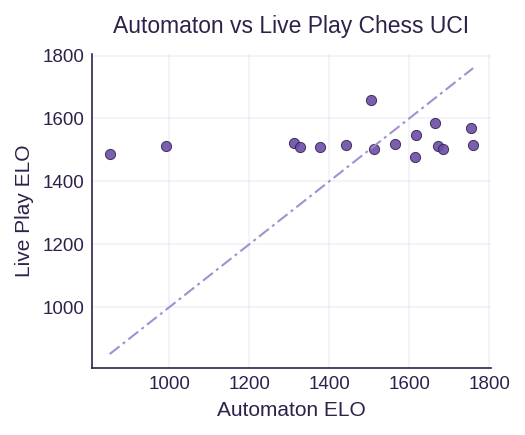

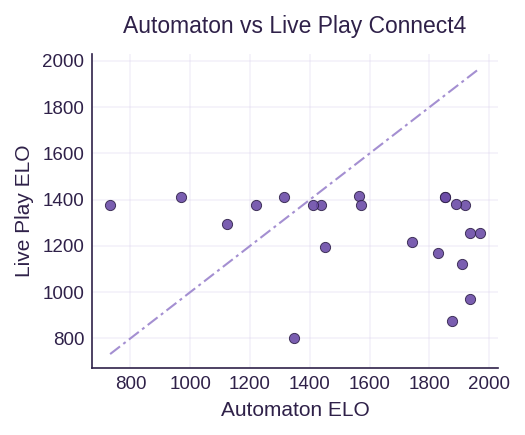

In [17]:
from temp_mem_plot import live_play_plot
live_play_plot(elos_live_rwins['Chess UCI'], 'Chess UCI')
live_play_plot(elos_live_rwins['Connect4'], 'Connect4')


# Cost Analysis

In [22]:
import json
from pathlib import Path
from collections import defaultdict

lives = defaultdict(lambda: defaultdict(list))  # game_world -> model_name -> list of json
live_prices = defaultdict(lambda: defaultdict(list))  # game_world -> model_name -> list of prices
live_price_per_prompt = defaultdict(lambda: defaultdict(list))  # game_world -> model_name -> list of prices
game_lengths = defaultdict(list)  # game_world -> list of game lengths
live_dir = Path("results_side_experiments/results_live")
for fp in live_dir.glob("**/*.json"):
    game_world = fp.parent.name
    model_name = fp.parent.parent.name
    with open(fp, "r") as f:
        data = json.load(f)
    if not data['done']:
        continue
    lives[game_world][model_name].append(data)


for game_world in lives:
    for model_name in lives[game_world]:
        for j in lives[game_world][model_name]:
            total_cost = j.get('live_play', {}).get('total_cost', None)
            api_responses = j.get('live_play', {}).get('api_responses', [])
            costs = [r.get('usage', {}).get('cost', None) for r in api_responses]
            live_price_per_prompt[game_world][model_name].extend(costs)
            if total_cost is None or total_cost == 0:
                continue
            live_prices[game_world][model_name].append(total_cost)
            if j['done'] and api_responses:
                game_lengths[game_world].append(len(api_responses))
# live_prices
root_dir = Path("src/game_arena")
automata_prices = defaultdict(lambda: defaultdict(list))
automata_tokens = defaultdict(lambda: defaultdict(list))

for fp in root_dir.glob(f"**/*.json"):
    relative_path = fp.relative_to(root_dir)
    top_dir = relative_path.parts[0]
    if top_dir.startswith('stanford') or top_dir.startswith('z_arc'):
        continue
    game = fp.parent.parent.parent.parent.parent.name  # game / examples / world / model / 001 / .json
    world = fp.parent.parent.parent.name
    game_world = f"{game}_{world}"
    model_name = fp.parent.parent.name
    try:
        data = json.loads(fp.read_text())
    except json.JSONDecodeError as e:
        print(f"Error decoding JSON file: {fp}")
        print(f"Error: {e}")
        continue
    if 'usage' in data:
        automata_prices[game_world][model_name].append(data['usage']['cost'])
        automata_tokens[game_world][model_name].append(data['usage']['total_tokens'])



In [23]:
df_automata = pd.DataFrame(
    [(k1, k2, v) for k1, d2 in automata_prices.items() for k2, vs in d2.items() for v in vs],
    columns=["game","model","v"]
)
df_automata['game'] = df_automata['game'].str.split('_').str[0]

df_automata = df_automata.rename(columns={'v':'price_per_automata'})
df_automata = df_automata.groupby(["model","game"], as_index=False)["price_per_automata"].mean()
df_automata['mean_per_tournament'] = df_automata['price_per_automata'] * 5
df_automata[['game','model','mean_per_tournament']]

,game,model,mean_per_tournament
0,amazons,claude_opus_4.5,0.21
1,backgammon,claude_opus_4.5,0.32
2,breakthrough,claude_opus_4.5,0.26
3,checkers,claude_opus_4.5,0.31
4,chess,claude_opus_4.5,0.42
...,...,...,...
814,mancala,trinity_mini_free,0.00
815,nim,trinity_mini_free,0.00
816,othello,trinity_mini_free,0.00
817,pentago,trinity_mini_free,0.00


In [24]:
df = pd.DataFrame(
    [(k1, k2, v) for k1, d2 in live_price_per_prompt.items() for k2, vs in d2.items() for v in vs],
    columns=["game","model","v"]
)
out = df.groupby(["game","model"])["v"].agg(mean="mean", v=list).reset_index()
out = out[out['mean'] > 0]
df = pd.DataFrame([(k, v) for k, vs in game_lengths.items() for v in vs], columns=["game","length"])
game_lens = df.groupby("game")["length"].agg(mean="mean", v=list).reset_index().set_index("game")['mean'].to_dict()
game_lens = {k.split('_')[0]: v for k, v in game_lens.items()}
out = out.rename(columns={'mean':'mean_price_per_prompt'})
out['game'] = out['game'].str.split('_').str[0]
out['mean_len'] = out['game'].map(game_lens)
out['mean_per_match'] = out['mean_price_per_prompt'] * out['mean_len']
out['mean_per_tournament'] = out['mean_per_match'] * 60
df_live = out[['game','model','mean_per_tournament']].reset_index(drop=True)
df_live


,game,model,mean_per_tournament
0,chess,deepseek_chat_v3_0324,1.64
1,chess,deepseek_v3.2,1.26
2,chess,gemini_2.0_flash_001,0.23
3,chess,gemini_3_flash_preview,1.18
4,chess,gpt_4o_mini,0.33
5,chess,gpt_5_mini,9.47
6,chess,gpt_oss_120b,1.72
7,chess,grok_code_fast_1,20.56
8,chess,kat_coder_pro,0.25
9,chess,minimax_m2,33.01


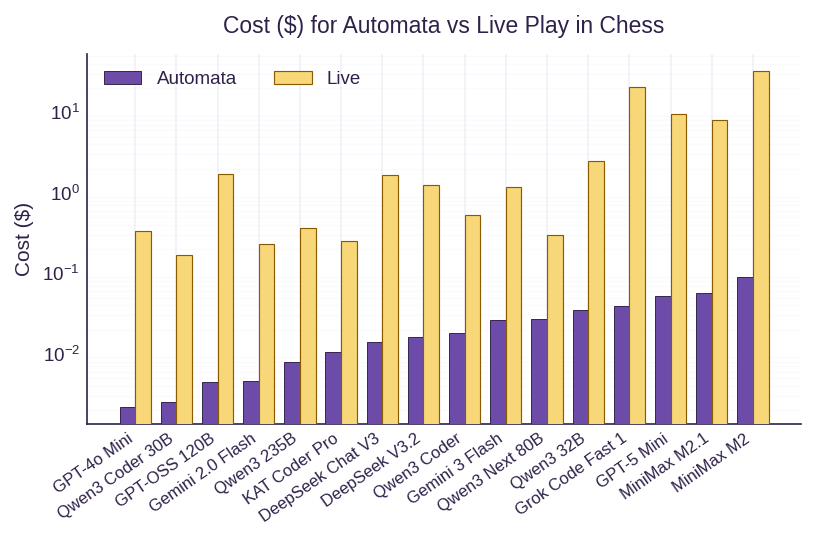

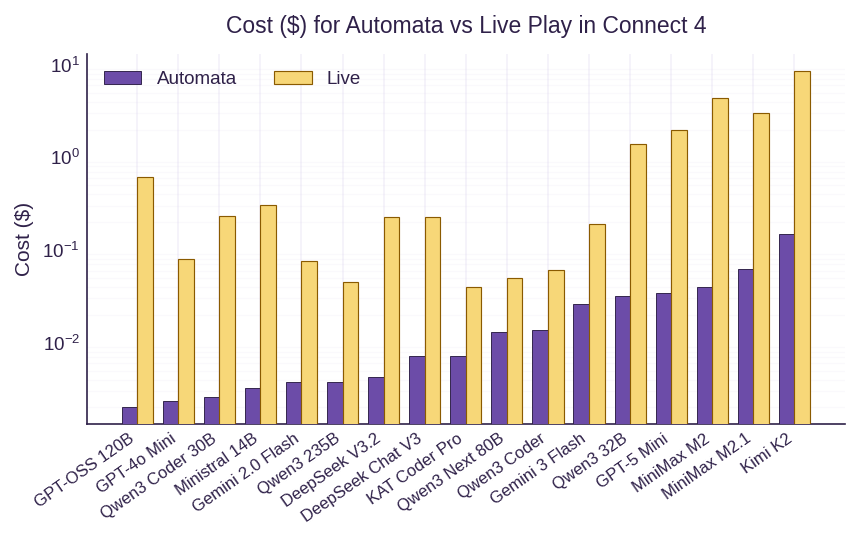

In [25]:
combined_df = tbl = (df_automata.merge(df_live, on=["model","game"], how="outer", suffixes=("_automata","_live"))
       .rename(columns={"mean_per_tournament_automata":"Automata", "mean_per_tournament_live":"Live"})
       [["model","game","Automata","Live"]])
combined_df = combined_df[combined_df['Live'].notna()]

from temp_mem_plot import cost_bar_plot
cost_bar_plot(combined_df[combined_df['game'] == 'chess'], 'Cost ($) for Automata vs Live Play in Chess', 'cost_live_vs_automata_chess', model_name_map)
cost_bar_plot(combined_df[combined_df['game'] == 'connect4'], 'Cost ($) for Automata vs Live Play in Connect 4', 'cost_live_vs_automata_connect4', model_name_map)
# 

# Engine again

## Generate Data

In [3]:
import time
import json
from datetime import datetime

from typing import Optional

from game_arena.typing import BotPath
from src.game_arena import utils
from src.game_arena import base
from src.game_arena import run_leaderboard
from src.game_arena.run_leaderboard import _load_previous_results, _build_todo_with_resume
from src.game_arena.utils import setup_logging

logger = setup_logging("run_leaderboard_notebook.log", "run_leaderboard", to_stdout=True)


def main_leaderboard(
        game_str: str,
        world: str,
        n_games: int,
        timeout: int,
        save_results_dir: str,
        max_workers: int,
        inject_bots,
        inject_vs_inject: bool = False,
        seed: Optional[int] = None,
        quals_dir: Optional[str] = None,
        top_k_model_bots: Optional[int] = None,
        skip_save_results: bool = False,
        model_blacklist: Optional[list[str]] = None,
        model_whitelist: Optional[list[str]] = None,
    ):
    logger.info(f'Starting leaderboard for game {game_str}, world {world}: n_games = {n_games}, timeout = {timeout}, save_results_dir = {save_results_dir}, max_workers = {max_workers}, seed = {seed}, quals_dir = {quals_dir}, top_k_model_bots = {top_k_model_bots}, skip_save_results = {skip_save_results}, model_blacklist = {model_blacklist}, model_whitelist = {model_whitelist}')
    game = utils.get_game(game_name=game_str)
    main_world = world
    if '&' in world:
        main_world = world.split('&')[0]
    config = utils.get_config_file(game_str, main_world)
    if '&' not in world:
        bots: list[BotPath] = list(utils.get_bot_paths_from_world(game_str, world, add_random=True).items())
    else:
        bots = []
        for world_part in world.split('&'):
            cur = list(utils.get_bot_paths_from_world(game_str, world_part, add_random=True).items())
            cur = [(f'{world_part}:{bot_name}', bot_path) for bot_name, bot_path in cur]
            bots.extend(cur)
    print(f'n bots = {len(bots)}')
    assert len(bots) > 1, f'Need at least 2 bots to run a leaderboard. Got {len(bots)} bots. in game {game_str}, world {world}'
    def game_creator():
        return game(config)
    game_creator.__name__ = game.__name__

    if model_blacklist is not None:
        pre_filtered_len = len(bots)
        bots = [b for b in bots if b[0].split('/')[0] not in model_blacklist]
        print(f'pre-blacklisting #bots = {pre_filtered_len}, post-blacklisting #bots = {len(bots)}')

    if model_whitelist is not None:
        pre_filtered_len = len(bots)
        bots = [b for b in bots if b[0].split('/')[0] in model_whitelist]
        print(f'pre-whitelisting #bots = {pre_filtered_len}, post-whitelisting #bots = {len(bots)}')

    pre_filtered_len = len(bots)
    qual_bot_names = None
    if quals_dir is not None:
        assert top_k_model_bots is not None, "top_k_model_bots is required when quals_json is provided"
        quals_json = utils.get_root_path() / Path(quals_dir) / f'matches_quals_{game_str}_{world}.json'
        assert quals_json.exists(), f"Quals JSON file not found {quals_json}"
        with open(quals_json, 'r') as f:
            quals_data = json.load(f)
        ci_rankings = quals_data['ci_rankings']
        qual_bot_names = set(['random'])
        for model_name, rankings in ci_rankings.items():
            qual_bots_sorted = sorted(rankings, key=lambda x: x['rating'] if x.get('rating') is not None else 0, reverse=True)
            top_k_bot_names = [e['bot'] for e in qual_bots_sorted[:top_k_model_bots]]
            qual_bot_names.update(top_k_bot_names)
        bots = [b for b in bots if b[0] in qual_bot_names]
        del quals_data
    post_filtered_len = len(bots)
    print(f'pre-filtered #bots = {pre_filtered_len}, post-filtered #bots = {post_filtered_len}')

    run_config = {'game_str': game_str, 'world': world, 'timeout': timeout, 'seed': seed}
    final_result_path = utils.get_root_path() / Path(save_results_dir) / f'matches_{game_str}_{world}.json'
    global_results = _load_previous_results(final_result_path, run_config, qual_bot_names)
    todo = run_leaderboard._build_todo_with_resume_A_vs_B(inject_bots, bots, n_games, global_results.get('match_results', []))
    if inject_vs_inject:
        todo += _build_todo_with_resume(inject_bots, n_games, global_results.get('match_results', []))
    print(f'game = {game_str}, world = {world}, len(todo) = {len(todo)}')
    if len(todo) == 0:
        print('No games to play. Exiting.')
        return
    cur_id = datetime.now().strftime('%Y_%m_%d_%H_%M_%S')
    start_time = time.time()
    logger.info(f'game = {game_str}, world = {world}, #pre-filtered bots = {pre_filtered_len}, #post-filtered bots = {post_filtered_len}, #todo = {len(todo)}, n_games = {n_games}, timeout = {timeout}, max_workers = {max_workers}. start time: {start_time}. {cur_id}')
    print('TRUE TOURNAMENT:')

    result = base.play_all_2p_games(
        game,
        config,
        todo,
        seed=seed,
        timeout=timeout,
        max_workers=max_workers,
    )
    global_results['match_results'].extend(result)
    

    elapsed_time = time.time() - start_time
    logger.info(f'done playing all games {game_str}, world = {world}. elapsed minutes: {elapsed_time / 60:.2f}. {cur_id}')

    if skip_save_results:
        print('skipping saving results')
        return
    final_result_path.parent.mkdir(parents=True, exist_ok=True)
    with open(final_result_path, 'w') as f:
        json.dump(global_results, f, indent=2)


### chess

#### heuristics vs each other

In [4]:
from src.heuristic.chess_01.play_heuristic_vs_bot import _load_passthrough_policy, _load_heuristic_policy
# from src.heuristic.chess_02.play_sunfish_vs_random import _load_sunfish_policy
to_inject = [
    # ('github_0_star', _load_passthrough_policy()),
    # ('github_0_star_modified', _load_heuristic_policy()),
    ('sunfish', Path('src/heuristic/chess_02/passthrough.py')),
    ('stockfish 18', Path('src/heuristic/chess_stockfish_18/passthrough.py')),
    ('stockfish 9', Path('src/heuristic/chess_stockfish_9/passthrough.py')),
    ('stockfish 3', Path('src/heuristic/chess_stockfish_3/passthrough.py')),
    ('stockfish 2', Path('src/heuristic/chess_stockfish_2/passthrough.py')),
    ('stockfish 1', Path('src/heuristic/chess_stockfish_1/passthrough.py')),
    ('lc0 20', Path('src/heuristic/chess_lc0_0_20/passthrough.py')),
]
model_blacklist, model_whitelist = run_leaderboard.get_model_blacklist_whitelist('src/experimental/model_ignore.json', None, None, None)

main_leaderboard(
    game_str='chess',
    world='worlduci1',
    n_games=8,
    timeout=5,
    top_k_model_bots=2,
    max_workers=50,
    seed=0,
    inject_bots=to_inject,
    inject_vs_inject=True,
    quals_dir="results_current/results_somerset_sept_5/quals/",
    save_results_dir='results_side_experiments/results_heuristic/sept_15',
    model_whitelist=model_whitelist,
    # model_whitelist=['gpt_5.5_xhigh'],
    # model_whitelist=[],
    model_blacklist=model_blacklist,
)

2026-09-15 07:24:09,457 - run_leaderboard - INFO - 1383569126.py:33 - Starting leaderboard for game chess, world worlduci1: n_games = 8, timeout = 5, save_results_dir = results_side_experiments/results_heuristic/sept_15, max_workers = 50, seed = 0, quals_dir = results_current/results_somerset_sept_5/quals/, top_k_model_bots = 2, skip_save_results = False, model_blacklist = ['claude_sonnet_4', 'gemini_2.5_flash', 'claude_sonnet_4.5_max', 'claude_opus_4.5_max', 'claude_opus_4.6_max', 'gpt_5.2_pro', 'claude_opus_4.6_medium', 'glm_5.3', 'claude_opus_4.6_low', 'gpt_5.4', 'gpt_5.5_minimal', 'deepseek_v3.2_speciale'], model_whitelist = None


n bots = 306
pre-blacklisting #bots = 306, post-blacklisting #bots = 297
pre-filtered #bots = 297, post-filtered #bots = 105
2026-09-15 07:24:12,374 - run_leaderboard - INFO - run_leaderboard.py:244 - loading existing results with 125116 previous match results from /storage/arkareem/projects/arena/CA_arena_victoria_fail_sep_7/results_side_experiments/results_heuristic/sept_15/matches_chess_worlduci1.json
game = chess, world = worlduci1, len(todo) = 0
No games to play. Exiting.


In [24]:
from src.heuristic.chess_01.play_heuristic_vs_bot import _load_passthrough_policy, _load_heuristic_policy
# from src.heuristic.chess_02.play_sunfish_vs_random import _load_sunfish_policy
to_inject = [
    ('lc0 20', Path('src/heuristic/chess_lc0_0_20/passthrough.py')),
]
model_blacklist, model_whitelist = run_leaderboard.get_model_blacklist_whitelist('src/experimental/model_ignore.json', None, None, None)

main_leaderboard(
    game_str='chess',
    world='worlduci1',
    n_games=20,
    timeout=25,
    top_k_model_bots=2,
    max_workers=50,
    seed=42,
    inject_bots=to_inject,
    inject_vs_inject=True,
    quals_dir="results_current/results_somerset_may_5/quals/",
    save_results_dir='results_side_experiments/results_heuristic/new_may_12_h_vs_h',
    # model_whitelist=model_whitelist,
    # model_whitelist=['gpt_5.5_xhigh'],
    model_whitelist=['random'],
    model_blacklist=model_blacklist,
)

2026-05-13 02:17:57,842 - run_leaderboard - INFO - 1383569126.py:33 - Starting leaderboard for game chess, world worlduci1: n_games = 20, timeout = 25, save_results_dir = results_side_experiments/results_heuristic/new_may_12_h_vs_h, max_workers = 50, seed = 42, quals_dir = results_current/results_somerset_may_5/quals/, top_k_model_bots = 2, skip_save_results = False, model_blacklist = ['claude_opus_4.6_low', 'gemini_2.5_flash', 'gpt_5.5_minimal', 'claude_sonnet_4', 'gpt_5.4', 'claude_sonnet_4.5_max', 'claude_opus_4.5_max', 'claude_opus_4.6_max', 'deepseek_v3.2_speciale', 'claude_opus_4.6_medium', 'gpt_5.2_pro'], model_whitelist = ['random']


n bots = 270
pre-blacklisting #bots = 270, post-blacklisting #bots = 262
pre-whitelisting #bots = 262, post-whitelisting #bots = 1
pre-filtered #bots = 1, post-filtered #bots = 1
2026-05-13 02:17:59,137 - run_leaderboard - INFO - run_leaderboard.py:258 - no previous results found at /storage/arkareem/projects/synthesis/arena/CA_arena/results_side_experiments/results_heuristic/new_may_12_h_vs_h/matches_chess_worlduci1.json. Creating new results file.
game = chess, world = worlduci1, len(todo) = 1
2026-05-13 02:17:59,138 - run_leaderboard - INFO - 1383569126.py:94 - game = chess, world = worlduci1, #pre-filtered bots = 1, #post-filtered bots = 1, #todo = 1, n_games = 20, timeout = 25, max_workers = 50. start time: 1778653079.1382463. 2026_05_13_02_17_59
TRUE TOURNAMENT:
2026-05-13 02:17:59,139 - game - INFO - base.py:397 - Playing a total of 40 games of ChessGame for 1 pairs (single big multithreaded loop)


Creating futures, this should only take a few seconds: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:00<00:00, 1476.72it/s]

Output()

2026-05-13 02:18:49,202 - game - INFO - base.py:270 - Timeout in play_game_with_timeout. Game: ChessGame Players: lc0 20, random Timeout: 25 seconds
2026-05-13 02:18:49,206 - game - INFO - base.py:270 - Timeout in play_game_with_timeout. Game: ChessGame Players: random, lc0 20 Timeout: 25 seconds
2026-05-13 02:18:49,206 - game - INFO - base.py:270 - Timeout in play_game_with_timeout. Game: ChessGame Players: lc0 20, random Timeout: 25 seconds
2026-05-13 02:18:49,206 - game - INFO - base.py:270 - Timeout in play_game_with_timeout. Game: ChessGame Players: random, lc0 20 Timeout: 25 seconds
2026-05-13 02:18:49,207 - game - INFO - base.py:270 - Timeout in play_game_with_timeout. Game: ChessGame Players: lc0 20, random Timeout: 25 seconds
2026-05-13 02:18:49,218 - game - INFO - base.py:270 - Timeout in play_game_with_timeout. Game: ChessGame Players: random, lc0 20 Timeout: 25 seconds
2026-05-13 02:18:49,219 - game - INFO - base.py:270 - Timeout in play_game_with_timeout. Game: ChessGame P

2026-05-13 02:18:49,343 - run_leaderboard - INFO - 1383569126.py:108 - done playing all games chess, world = worlduci1. elapsed minutes: 0.84. 2026_05_13_02_17_59


#### main

In [9]:

to_inject = [
    # ('sunfish', Path('src/heuristic/chess_02/passthrough.py')),
    # ('stockfish 18', Path('src/heuristic/chess_stockfish_18/passthrough.py')),
    # ('stockfish 9', Path('src/heuristic/chess_stockfish_9/passthrough.py')),
    # ('stockfish 3', Path('src/heuristic/chess_stockfish_3/passthrough.py')),
    # ('stockfish 2', Path('src/heuristic/chess_stockfish_2/passthrough.py')),
    ('stockfish 1', Path('src/heuristic/chess_stockfish_1/passthrough.py')),
    # ('lc0 20', Path('src/heuristic/chess_lc0_0_20/passthrough.py')),
]
model_blacklist, model_whitelist = run_leaderboard.get_model_blacklist_whitelist('src/experimental/model_ignore.json', None, None, None)
main_leaderboard(
    game_str='chess',
    world='worlduci1',
    n_games=20,
    # n_games=1,
    timeout=5,
    top_k_model_bots=2,
    max_workers=50,
    seed=42,
    inject_bots=to_inject,
    inject_vs_inject=False,
    quals_dir="results_current/results_somerset_may_5/quals/",
    save_results_dir='results_side_experiments/results_heuristic/new_may_12_stockfish_1',
    model_whitelist=model_whitelist,
    # model_whitelist=['solar_pro_3_free'],
    # model_whitelist=['gpt_5.5_xhigh'],
    # model_whitelist=['gpt_5.4_low'],
    # model_whitelist=['random'],
    model_blacklist=model_blacklist,
)


2026-05-14 02:32:23,226 - run_leaderboard - INFO - 1383569126.py:33 - Starting leaderboard for game chess, world worlduci1: n_games = 20, timeout = 5, save_results_dir = results_side_experiments/results_heuristic/new_may_12_stockfish_1, max_workers = 50, seed = 42, quals_dir = results_current/results_somerset_may_5/quals/, top_k_model_bots = 2, skip_save_results = False, model_blacklist = ['gpt_5.4', 'deepseek_v3.2_speciale', 'gpt_5.5_minimal', 'gpt_5.2_pro', 'claude_opus_4.6_low', 'claude_sonnet_4', 'claude_opus_4.6_max', 'claude_opus_4.5_max', 'gemini_2.5_flash', 'claude_sonnet_4.5_max', 'claude_opus_4.6_medium'], model_whitelist = None
n bots = 270
pre-blacklisting #bots = 270, post-blacklisting #bots = 262
pre-filtered #bots = 262, post-filtered #bots = 91
2026-05-14 02:32:24,816 - run_leaderboard - INFO - run_leaderboard.py:244 - loading existing results with 40 previous match results from /storage/arkareem/projects/synthesis/arena/CA_arena/results_side_experiments/results_heurist

Creating futures, this should only take a few seconds: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3600/3600 [00:00<00:00, 23738.25it/s]

Output()

2026-05-14 02:33:24,866 - game - INFO - base.py:222 - Game execution took 60.0s for players claude_opus_4.5/005 and stockfish 1; seed 32848; last action history: (0, 'g7g6', 0.03) (len: 42) (thinking_status: (1, 1778740399.7136223))
2026-05-14 02:33:24,891 - game - INFO - base.py:222 - Game execution took 60.0s for players claude_opus_4.5/005 and stockfish 1; seed 718; last action history: (0, 'g7g6', 0.03) (len: 42) (thinking_status: (1, 1778740399.6144845))
2026-05-14 02:33:24,923 - game - INFO - base.py:222 - Game execution took 60.1s for players claude_opus_4.5/005 and stockfish 1; seed 1640; last action history: (0, 'g7g6', 0.04) (len: 42) (thinking_status: (1, 1778740399.6493971))


2026-05-14 02:33:25,130 - game - INFO - base.py:222 - Game execution took 60.3s for players claude_opus_4.5/005 and stockfish 1; seed 29101; last action history: (0, 'g7g6', 0.04) (len: 42) (thinking_status: (1, 1778740399.876925))


...

2026-05-14 03:12:51,494 - game - INFO - base.py:222 - Game execution took 60.0s for players gpt_5.4_medium/005 and stockfish 1; seed 1632; last action history: (0, 'e7d8', 0.9) (len: 36) (thinking_status: (1, 1778742766.439848))


2026-05-14 03:12:53,338 - game - INFO - base.py:222 - Game execution took 60.0s for players gpt_5.4_medium/005 and stockfish 1; seed 63266; last action history: (1, 'f3e4', 2.51) (len: 35) (thinking_status: (0, 1778742767.6115084))


2026-05-14 03:13:18,746 - game - INFO - base.py:222 - Game execution took 60.1s for players gpt_5.4_medium/005 and stockfish 1; seed 45255; last action history: (0, 'c8a6', 0.64) (len: 34) (thinking_status: (1, 1778742791.2265358))


2026-05-14 03:13:26,690 - game - INFO - base.py:222 - Game execution took 60.1s for players gpt_5.4_medium/005 and stockfish 1; seed 15369; last action history: (0, 'e7d8', 0.9) (len: 36) (thinking_status: (1, 1778742801.3369503))


2026-05-14 03:14:18,908 - run_leaderboard - INFO - 1383569126.py:108 - done playing all games chess, world = worlduci1. elapsed minutes: 41.90. 2026_05_14_02_32_24


### checkers

In [4]:
# need to:
# pip install loguru
# pip install uvicorn
# pip install fastapi
from src.heuristic.checkers_01.play_draughts_vs_random import _load_draughts_policy
to_inject = [
    # ('github_0_star', _load_passthrough_policy()),
    # ('github_0_star_modified', _load_heuristic_policy()),
    ('alpha_beta', Path('src/heuristic/checkers_01/passthrough.py')),
]
model_blacklist, model_whitelist = run_leaderboard.get_model_blacklist_whitelist('src/experimental/model_ignore.json', None, None, None)

main_leaderboard(
    game_str='checkers',
    world='world1',
    n_games=2,
    timeout=5,
    top_k_model_bots=2,
    max_workers=32,
    inject_bots=to_inject,
    quals_dir="results_current/results_somerset_sept_5/quals/",
    save_results_dir='results_side_experiments/results_heuristic/sept_5_checkers',
    model_whitelist=model_whitelist,
    # model_whitelist=['gpt_5_mini'],
    # model_whitelist=['glm_5'],
    model_blacklist=model_blacklist,
)


2026-09-25 15:56:59,740 - run_leaderboard - INFO - 1657373440.py:33 - Starting leaderboard for game checkers, world world1: n_games = 2, timeout = 5, save_results_dir = results_side_experiments/results_heuristic/sept_5_checkers, max_workers = 32, seed = None, quals_dir = results_current/results_somerset_sept_5/quals/, top_k_model_bots = 2, skip_save_results = False, model_blacklist = ['claude_sonnet_4', 'claude_opus_4.5_max', 'claude_opus_4.6_max', 'glm_5.3', 'gpt_5.2_pro', 'gpt_5.5_minimal', 'gemini_2.5_flash', 'gpt_5.4', 'claude_opus_4.6_medium', 'claude_sonnet_4.5_max', 'deepseek_v3.2_speciale', 'claude_opus_4.6_low'], model_whitelist = None


n bots = 308
pre-blacklisting #bots = 308, post-blacklisting #bots = 297
pre-filtered #bots = 297, post-filtered #bots = 105
2026-09-25 15:57:00,991 - run_leaderboard - INFO - run_leaderboard.py:244 - loading existing results with 420 previous match results from /storage/arkareem/projects/arena/CA_arena_victoria_fail_sep_7/results_side_experiments/results_heuristic/sept_5_checkers/matches_checkers_world1.json
game = checkers, world = world1, len(todo) = 0
No games to play. Exiting.


### othelo

In [ ]:
from src.heuristic.othello_01.heuristic import policy
to_inject = [
    ('negmax', Path('src/heuristic/othello_01/heuristic.py')),
]
model_blacklist, model_whitelist = run_leaderboard.get_model_blacklist_whitelist('src/experimental/model_ignore.json', None, None, None)

main_leaderboard(
    game_str='othello',
    world='world1',
    n_games=5,
    timeout=1,
    top_k_model_bots=2,
    max_workers=32,
    inject_bots=to_inject,
    quals_dir="results_current/results_somerset_feb_21/quals/",
    save_results_dir='results_side_experiments/results_heuristic/new_apr_27',
    # model_whitelist=model_whitelist,
    model_whitelist=['gemini_3_pro_preview', 'gpt_5.2'],
    model_blacklist=model_blacklist,
)


2026-04-27 20:00:24,919 - run_leaderboard - INFO - 815896955.py:32 - Starting leaderboard for game othello, world world1: n_games = 5, timeout = 1, save_results_dir = results_side_experiments/results_heuristic/new_apr_27, max_workers = 32, seed = None, quals_dir = results_current/results_somerset_feb_21/quals/, top_k_model_bots = 2, skip_save_results = False, model_blacklist = ['gpt_5.2_pro', 'claude_opus_4.6_max', 'deepseek_v3.2_speciale', 'claude_sonnet_4', 'gemini_2.5_flash', 'claude_sonnet_4.5_max', 'claude_opus_4.5_max'], model_whitelist = ['gemini_3_pro_preview', 'gpt_5.2']


n bots = 235
pre-blacklisting #bots = 235, post-blacklisting #bots = 233
pre-whitelisting #bots = 233, post-whitelisting #bots = 12
pre-filtered #bots = 12, post-filtered #bots = 4
2026-04-27 20:00:25,642 - run_leaderboard - INFO - run_leaderboard.py:244 - loading existing results with 138 previous match results from /storage/ANON/projects/synthesis/arena/CA_arena/results_side_experiments/results_heuristic/new_apr_27/matches_othello_world1.json
game = othello, world = world1, len(todo) = 4
2026-04-27 20:00:25,643 - run_leaderboard - INFO - 815896955.py:92 - game = othello, world = world1, #pre-filtered bots = 12, #post-filtered bots = 4, #todo = 4, n_games = 5, timeout = 1, max_workers = 32. start time: 1777334425.6435695. 2026_04_27_20_00_25
TRUE TOURNAMENT:
2026-04-27 20:00:25,644 - game - INFO - base.py:397 - Playing a total of 32 games of OthelloGame for 4 pairs (single big multithreaded loop)


Creating futures, this should only take a few seconds: 100%|██████████| 32/32 [00:00<00:00, 1534.90it/s]

Output()

2026-04-27 20:01:08,087 - run_leaderboard - INFO - 815896955.py:106 - done playing all games othello, world = world1. elapsed minutes: 0.71. 2026_04_27_20_00_25


### go

In [22]:
to_inject = [
    ('negmax', Path('src/heuristic/go_01/heuristic.py')),
]
model_blacklist, model_whitelist = run_leaderboard.get_model_blacklist_whitelist('src/experimental/model_ignore.json', None, None, None)

main_leaderboard(
    game_str='go',
    world='world1',
    n_games=5,
    timeout=1,
    top_k_model_bots=2,
    max_workers=32,
    inject_bots=to_inject,
    quals_dir="results_current/results_somerset_feb_21/quals/",
    save_results_dir='results_side_experiments/results_heuristic/new_apr_27',
    model_whitelist=model_whitelist,
    # model_whitelist=['gemini_3_pro_preview', 'gpt_5.2'],
    model_blacklist=model_blacklist,
)



2026-04-27 21:28:59,695 - run_leaderboard - INFO - 815896955.py:32 - Starting leaderboard for game go, world world1: n_games = 5, timeout = 1, save_results_dir = results_side_experiments/results_heuristic/new_apr_27, max_workers = 32, seed = None, quals_dir = results_current/results_somerset_feb_21/quals/, top_k_model_bots = 2, skip_save_results = False, model_blacklist = ['gpt_5.2_pro', 'claude_opus_4.6_max', 'deepseek_v3.2_speciale', 'claude_sonnet_4', 'gemini_2.5_flash', 'claude_sonnet_4.5_max', 'claude_opus_4.5_max'], model_whitelist = None
n bots = 237
pre-blacklisting #bots = 237, post-blacklisting #bots = 233
pre-filtered #bots = 233, post-filtered #bots = 69
2026-04-27 21:29:00,591 - run_leaderboard - INFO - run_leaderboard.py:244 - loading existing results with 690 previous match results from /storage/ANON/projects/synthesis/arena/CA_arena/results_side_experiments/results_heuristic/new_apr_27/matches_go_world1.json
game = go, world = world1, len(todo) = 69
2026-04-27 21:29:00,

Creating futures, this should only take a few seconds: 100%|██████████| 690/690 [00:00<00:00, 1648.44it/s]

Output()

2026-04-27 21:30:00,718 - game - INFO - base.py:222 - Game execution took 60.1s for players gemini_3_pro_preview/005 and negmax; seed None; last action history: (0, (6, 2), 0.0) (len: 361) (thinking_status: (1, 1777339799.6883245))
2026-04-27 21:30:00,718 - game - INFO - base.py:222 - Game execution took 60.1s for players gemini_3_pro_preview/005 and negmax; seed None; last action history: (0, (2, 16), 0.0) (len: 331) (thinking_status: (1, 1777339799.6874828))
2026-04-27 21:30:00,729 - game - INFO - base.py:222 - Game execution took 60.1s for players negmax and gemini_3_pro_preview/005; seed None; last action history: (1, (18, 11), 0.0) (len: 352) (thinking_status: (0, 1777339799.6190825))
2026-04-27 21:30:00,729 - game - INFO - base.py:222 - Game execution took 60.1s for players negmax and gemini_3_pro_preview/005; seed None; last action history: (1, (14, 19), 0.0) (len: 360) (thinking_status: (0, 1777339799.6695879))
2026-04-27 21:30:00,730 - game - INFO - base.py:222 - Game executio

2026-04-27 21:30:01,173 - game - INFO - base.py:222 - Game execution took 60.6s for players gemini_3_pro_preview/005 and negmax; seed None; last action history: (0, (14, 10), 0.0) (len: 365) (thinking_status: (1, 1777339800.1466324))
2026-04-27 21:30:01,205 - game - INFO - base.py:222 - Game execution took 60.6s for players negmax and gpt_5.2/005; seed None; last action history: (1, (16, 15), 0.01) (len: 258) (thinking_status: (0, 1777339799.88621))
2026-04-27 21:30:01,206 - game - INFO - base.py:222 - Game execution took 60.6s for players negmax and gemini_3_pro_preview/005; seed None; last action history: (1, (7, 5), 0.0) (len: 342) (thinking_status: (0, 1777339800.1388972))
2026-04-27 21:30:01,206 - game - INFO - base.py:222 - Game execution took 60.6s for players negmax and gpt_5.2/005; seed None; last action history: (1, (12, 19), 0.01) (len: 342) (thinking_status: (0, 1777339800.1241329))
2026-04-27 21:30:01,217 - game - INFO - base.py:222 - Game execution took 60.6s for players 

...

2026-04-27 22:01:43,981 - game - INFO - base.py:222 - Game execution took 120.2s for players claude_opus_4.5/001 and negmax; seed None; last action history: (1, (0, 0), 0.38) (len: 694) (thinking_status: (0, 1777341702.96869))


2026-04-27 22:01:44,901 - game - INFO - base.py:222 - Game execution took 90.2s for players gemini_3_pro_preview/001 and negmax; seed None; last action history: (0, (11, 10), 0.0) (len: 565) (thinking_status: (1, 1777341703.8893707))


2026-04-27 22:02:07,697 - game - INFO - base.py:222 - Game execution took 150.3s for players negmax and claude_opus_4.5/001; seed None; last action history: (0, (0, 0), 0.59) (len: 675) (thinking_status: (1, 1777341726.6868398))


2026-04-27 22:02:10,367 - game - INFO - base.py:222 - Game execution took 120.4s for players negmax and gemini_3_pro_preview/001; seed None; last action history: (1, (12, 8), 0.0) (len: 674) (thinking_status: (0, 1777341728.8871672))


2026-04-27 22:02:22,981 - run_leaderboard - INFO - 815896955.py:106 - done playing all games go, world = world1. elapsed minutes: 33.37. 2026_04_27_21_29_00


## leaderboard

In [5]:

gs = [
    # compare with stockfish
    # ['chess', 'worlduci1', 'results_current/results_somerset_may_5/tourney/matches_chess_worlduci1.json', 'results_side_experiments/results_heuristic/new_may_12_stockfish_1s/matches_chess_worlduci1.json', 'Chess'],
    # ['chess', 'worlduci1', 'results_current/results_somerset_may_5/tourney/matches_chess_worlduci1.json', 'results_side_experiments/results_heuristic/new_may_12_stockfish/matches_chess_worlduci1.json', 'Chess'],
    # ['chess', 'worlduci1', 'results_current/results_somerset_may_5/tourney/matches_chess_worlduci1.json', 'results_side_experiments/results_heuristic/new_may_12_sunfish/matches_chess_worlduci1.json', 'Chess'],
    # ['chess', 'worlduci1', 'results_current/results_somerset_may_5/tourney/matches_chess_worlduci1.json', 'results_side_experiments/results_heuristic/new_may_12/matches_chess_worlduci1.json', 'Chess'],
    # ['chess', 'worlduci1', 
    #     [
    #         'results_current/results_somerset_may_5/tourney/matches_chess_worlduci1.json', # base
    #         'results_side_experiments/results_heuristic/sept_15/matches_chess_worlduci1.json', # sept 15
    #         # 'results_side_experiments/results_heuristic/new_may_12_h_vs_h/matches_chess_worlduci1.json', # h vs h
    #         # 'results_side_experiments/results_heuristic/new_may_12_stockfish_18/matches_chess_worlduci1.json', # stockfish 18
    #         # 'results_side_experiments/results_heuristic/new_may_12_stockfish_9/matches_chess_worlduci1.json', # stockfish 9
    #         # 'results_side_experiments/results_heuristic/new_may_12_stockfish_3/matches_chess_worlduci1.json', # stockfish 3
    #         # 'results_side_experiments/results_heuristic/new_may_12_stockfish_2/matches_chess_worlduci1.json', # stockfish 2
    #         # 'results_side_experiments/results_heuristic/new_may_12_stockfish_1/matches_chess_worlduci1.json', # stockfish 1
    #         # 'results_side_experiments/results_heuristic/new_may_12_sunfish/matches_chess_worlduci1.json', # sunfish
    #         # 'results_side_experiments/results_heuristic/new_may_12_lc0_20/matches_chess_worlduci1.json', # lc0 20
    #         # 'results_side_experiments/results_heuristic/new_may_5/matches_chess_worlduci1.json',
    #     ], None, 'Chess'],

    # 2026 sept 24 checkers
    ['checkers', 'world1', 'results_current/results_somerset_sept_5/tourney/matches_checkers_world1.json', 'results_side_experiments/results_heuristic/sept_5_checkers/matches_checkers_world1.json', 'Checkers'],

    # 2026 may 6
    # ['chess', 'worlduci1', 'results_current/results_somerset_may_5/tourney/matches_chess_worlduci1.json', 'results_side_experiments/results_heuristic/new_may_5/matches_chess_worlduci1.json', 'Chess'],
    # ['checkers', 'world1', 'results_current/results_somerset_may_5/tourney/matches_checkers_world1.json', 'results_side_experiments/results_heuristic/new_may_5/matches_checkers_world1.json', 'Checkers'],

    # 2026 apr 27
    # ['chess', 'worlduci1', 'results_current/results_somerset_may_5/tourney/matches_chess_worlduci1.json', 'results_side_experiments/results_heuristic/new_apr_27/matches_chess_worlduci1.json', 'Chess'],

    # ['checkers', 'world1', 'results_current/results_somerset_feb_21/tourney/matches_checkers_world1.json', 'results_side_experiments/results_heuristic/new_apr_27/matches_checkers_world1.json', 'Checkers'],
    # ['othello', 'world1', 'results_current/results_somerset_feb_21/tourney/matches_othello_world1.json', 'results_side_experiments/results_heuristic/new_apr_27/matches_othello_world1.json', 'Othello'],

    # old
    # ['chess', 'worlduci1', 'results_side_experiments/results_heuristic/matches_chess_worlduci1_2080_5.json', 'results_side_experiments/results_heuristic/matches_chess_worlduci1_feb_22_sunfish-depth-5.json', 'Chess'],
    # ['checkers', 'world1', 'results_current/results_somerset_feb_20/tourney/matches_checkers_world1.json', 'results_side_experiments/results_heuristic/new/matches_checkers_world1.json', 'Checkers'],
    # ['checkers', 'world1', 'results_current/results_somerset_feb_20/tourney/matches_checkers_world1.json', 'results_side_experiments/results_heuristic/new/matches_checkers_world1.json', 'Checkers'],


]
bots_to_ignore = set([
    'lc0 20',
])


In [6]:
from src.experimental.lm_arena.simple_example import main_results
results = {}
for game_str, world, match_json, aug_json, colname in gs:
    print(f'{game_str} {world}')
    all_data_pruned = []
    if isinstance(match_json, str):
        all_data_pruned.extend(get_match_results(match_json))
    elif isinstance(match_json, list):
        for mj in match_json:
            all_data_pruned.extend(get_match_results(mj))
    if aug_json is not None:
        aug_data = get_match_results(aug_json)
    else:
        aug_data = []
    all_data_pruned.extend(aug_data)
    all_data_pruned = [m for m in all_data_pruned if m['name0'] not in bots_to_ignore and m['name1'] not in bots_to_ignore]
    # all_data_pruned = aug_data
    # results[colname] = main_results(all_data_pruned, rating_system='bt', exclude_tie=False, num_cpu=1, seed=42, only_model=False, num_bootstrap=10)
    results[colname] = main_results(all_data_pruned, rating_system='bt', exclude_tie=False, num_cpu=1, seed=42, only_model=True, num_bootstrap=10)

    # NO TIES
    # results[colname] = main_results(all_data_pruned, rating_system='bt', exclude_tie=True, num_cpu=1, seed=42, only_model=False, num_bootstrap=10)
    # results[colname] = main_results(all_data_pruned, rating_system='bt', exclude_tie=True, num_cpu=1, seed=42, only_model=True, num_bootstrap=10)


elos = []
for k in results:
    elos.append(pd.DataFrame(results[k]['elo_rating_final']).rename(columns={'rating': 'ELO'}))


checkers world1
Filtered 119020 matches to 27604 matches


Processing using <lambda>: 100%|██████████| 27604/27604 [00:00<00:00, 381112.09it/s]

Number of battles: 27604



100%|██████████| 10/10 [00:00<00:00, 31.12it/s]


In [7]:
df_dict = {}
for _,_,_,_,n in gs:
    matches = results[n]['raw_match_results']
    all_scores_df = run_leaderboard.get_scores_from_match_data(matches)
    all_scores_df['total_matches'] = all_scores_df.sum(axis=1)

    elos_df = pd.concat(elos, axis=1)
    elos_df.columns = [n for _,_,_,_,n in gs]
    df = pd.concat([all_scores_df, elos_df[colname].rename('ELO')], axis=1).round().astype("Int64")
    df.sort_values('ELO', ascending=False, inplace=True)
    df_dict[n] = df
    print(n)
    print(df_dict[n].iloc[:25].to_markdown())

Checkers
|                        |   win |   loss |   draw |   error |   timeout |   enemy_error |   enemy_timeout |   total_matches |   ELO |
|:-----------------------|------:|-------:|-------:|--------:|----------:|--------------:|----------------:|----------------:|------:|
| claude_fable_5.1_high  |   711 |      4 |     93 |       0 |         0 |           186 |              10 |            1004 |  2345 |
| gpt_6_astra_high       |   709 |      2 |    101 |       0 |         0 |           174 |              18 |            1004 |  2337 |
| kimi_k3                |   693 |      6 |    102 |       0 |         0 |           185 |              18 |            1004 |  2319 |
| gemini_3.8_flash       |   623 |     22 |    142 |      12 |         0 |           220 |              25 |            1044 |  2169 |
| alpha_beta             |   119 |     13 |     29 |       0 |         0 |            43 |               0 |             204 |  2108 |
| gpt_5.5_instant        |   613 |     47 |   

alpha_beta missing


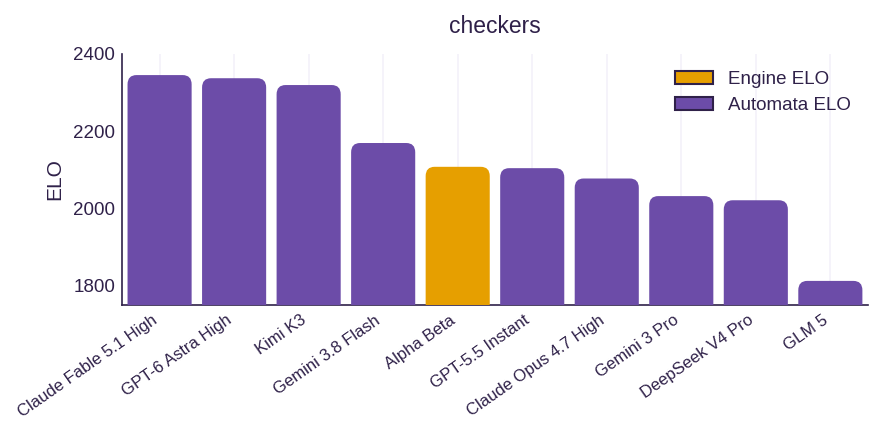

In [ ]:
from temp_mem_plot import engine_plot
# engine_plot(df_dict['Chess'], 'chess', model_name_map, save_plot=True, top_k=13)
engine_plot(elos_df['Checkers'], 'checkers', model_name_map)



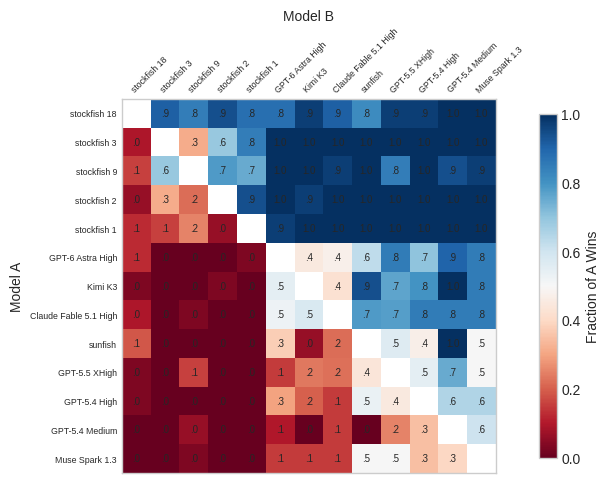

In [31]:
from temp_mem_plot import plot_pairwise_win_draw_matrices
from temp_mem_plot import plot_engine_matchups_heatmap

# chess_pairwise_win_rates, chess_pairwise_decisive_totals, chess_pairwise_draw_rates, chess_pairwise_totals = plot_pairwise_win_draw_matrices(
#     results['Chess']['raw_match_results'],
#     df_dict['Chess'],
#     model_name_map,
#     top_k=13,
#     save_plot=True,
# )
plot_engine_matchups_heatmap(
    results["Chess"]["raw_match_results"],
    df_dict["Chess"],
    top_k=13,
    cell_fontsize=7,
)


In [41]:
heuristic_names = ['sunfish', 'stockfish 18', 'stockfish 9', 'stockfish 3', 'lc0 20']
for m in matches:
    if m['r'] is None:
        continue
    if (m['name0'] in heuristic_names and m['winner'] != 0 and m['r']['player_err_counts'][0] == 1) or (m['name1'] in heuristic_names and m['winner'] != 1 and m['r']['player_err_counts'][1] == 1):
        print(m)
        print(m['r']['exception_traceback'])


# ELO Stability

In [3]:
NAME_DELETE = [  # these must be completely removed
    'deepseek_v3.2_speciale', 'claude_sonnet_4', 'gemini_2.5_flash', 'gpt_5.2_pro'
]
NAME_FIX_MAP = {
    # 'kat_coder_pro_free': 'kat_coder_pro',
    # 'kat_code_pro_free': 'kat_coder_pro',
}


In [21]:
gs = [
    # ['pentago', 'world1', None, 'Pentago'],
    # ['dots_and_boxes', 'world1', None, 'Dots&B'],
    ['checkers', 'world1', None, 'Checkers'],
]

raw_match_data = {}
for game_str, world, match_json, colname in gs:
    if match_json is None:
        try:
            match_json = get_match_file_path(game_str, world, result_dir=f'results_side_experiments/results_variance_checkers')
        except Exception as e:
            print(f'ERROR\nERROR\nERROR\nERROR {game_str} {world}: {e}')
            continue
    all_data_pruned = get_match_results(match_json)
    raw_match_data[colname] = all_data_pruned
game_str = list(raw_match_data.keys())[0]


In [22]:
d = raw_match_data[game_str]
random.shuffle(d)
# elo_post, top_models = run_leaderboard.get_elo_df_combined(d, combine_method='none', verbose=False, iters=4, learning_rate=4)
battles = _build_battles(d, "full", 0.0)
elo_post = compute_bt(battles)

K = 10
s = elo_post.sort_values(ascending=False)
top = s.head(K).to_dict()
mid = s.iloc[max(0, (len(s)-K)//2): max(0, (len(s)-K)//2) + K].to_dict()
bot = s.tail(K).to_dict()

# elo_dict = {
#     **top['ELO'],
#     **mid['ELO'],
#     **bot['ELO'],
# }
elo_dict = elo_post.to_dict()
print(elo_dict)


{'glm_4.7/001': 2463.064885744935, 'gpt_5.2_codex/005': 2404.3552746278433, 'tng_r1t_chimera_free/005': 2348.829221102948, 'glm_4.7/004': 2341.255590793119, 'claude_sonnet_4.5/004': 2297.7130476981956, 'tng_r1t_chimera_free/004': 2290.0076505894453, 'gemini_3_flash_preview/004': 2226.2225499893934, 'deepseek_chat_v3_0324/002': 2198.468091589776, 'qwen3_235b_a22b_2507/003': 2190.37948963105, 'random': 2168.460803226369, 'gemini_2.0_flash_001/001': 2159.877037876263, 'kat_coder_pro/005': 2145.4715200630753, 'gemini_3_pro_preview/004': 2138.776573877175, 'kat_coder_pro/001': 2123.089456236036, 'nemotron_nano_12b_v2_vl_free/002': 2118.1849575693104, 'qwen3_coder/001': 2087.4628283370844, 'nemotron_nano_12b_v2_vl_free/003': 2082.66494944596, 'deepseek_r1t2_chimera_free/003': 2079.472779027495, 'gemini_2.0_flash_001/002': 2077.878292659922, 'grok_code_fast_1/002': 2076.2847270079055, 'gemini_3_pro_preview/005': 2072.3041927573654, 'trinity_mini_free/004': 2071.508579177379, 'gpt_5.2_codex/00

In [58]:
# d = raw_match_data['Checkers']
# for name in elo_dict.keys():
#     removed_matches = [x for x in d if x['name0'] == name or x['name1'] == name]
#     print(name, len(removed_matches))


In [23]:
import random

def get_fracs(d, name, percents):
    removed_matches = [x for x in d if x['name0'] == name or x['name1'] == name]
    d_no_name = [x for x in d if x['name0'] != name and x['name1'] != name]
    assert len(removed_matches) == len(d) - len(d_no_name)
    elos_per_percent = {}
    for p in tqdm(percents, desc=f'name={name}'):
        num_to_include = int(len(removed_matches) * p / 100)
        cur_d = d_no_name + removed_matches[:num_to_include]
        random.shuffle(cur_d)
        battles = _build_battles(cur_d, "full", 0.0)
        elo_post = compute_bt(battles)
        # elo_post, top_models = run_leaderboard.get_elo_df_combined(cur_d, combine_method='none', verbose=False, iters=4, learning_rate=4)
        elos_per_percent[p] = elo_post.loc[name].item()
    return elos_per_percent

d = raw_match_data[game_str]
# percents = np.linspace(1, 100, 20)
percents = [1, 5, 10, 20, 40, 60, 80, 100]

all_names = set(x['name0'] for x in d) | set(x['name1'] for x in d)
all_names = list(all_names)
total_results = {}
for name in tqdm(elo_dict.keys(), desc='OUTER LOOP'):
    elos_per_percent = get_fracs(d, name, percents)
    total_results[name] = elos_per_percent



OUTER LOOP:   0%|          | 0/63 [00:00<?, ?it/s]

name=glm_4.7/001:   0%|          | 0/8 [00:00<?, ?it/s]

name=gpt_5.2_codex/005:   0%|          | 0/8 [00:00<?, ?it/s]

name=tng_r1t_chimera_free/005:   0%|          | 0/8 [00:00<?, ?it/s]

name=glm_4.7/004:   0%|          | 0/8 [00:00<?, ?it/s]

...

name=deepseek_v3.2/002:   0%|          | 0/8 [00:00<?, ?it/s]

name=qwen3_coder/002:   0%|          | 0/8 [00:00<?, ?it/s]

name=devstral_2512_free/002:   0%|          | 0/8 [00:00<?, ?it/s]

name=devstral_2512_free/001:   0%|          | 0/8 [00:00<?, ?it/s]

name=ministral_14b_2512/002:   0%|          | 0/8 [00:00<?, ?it/s]

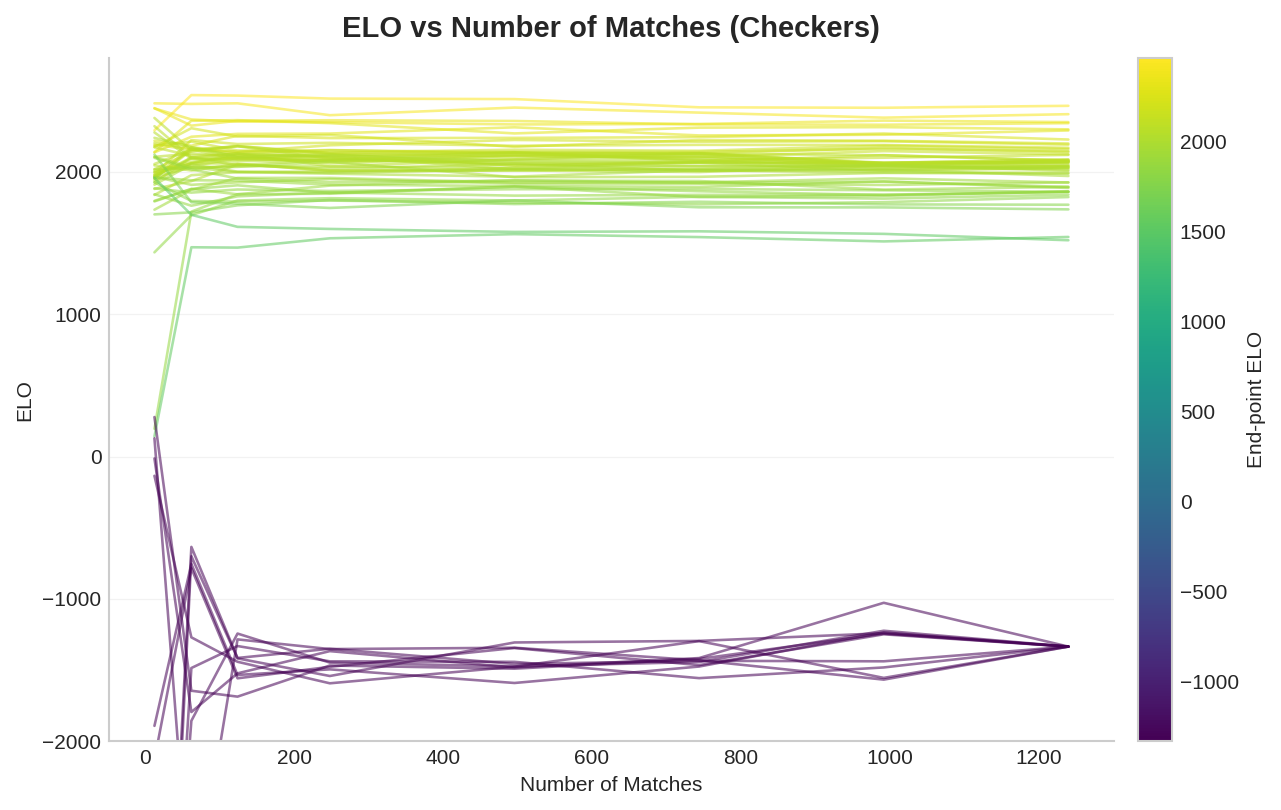

In [ ]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)
game_str_title = {
    'Dots&B': 'Dots & Boxes',
}.get(game_str, game_str)
cmap = plt.get_cmap("viridis")
vals = np.array(list(elo_dict.values()), dtype=float)
norm = plt.Normalize(vmin=float(vals.min()), vmax=float(vals.max()))

for name, dd in total_results.items():
    N = len([x for x in d if x["name0"] == name or x["name1"] == name])
    x_pct, y = zip(*sorted(dd.items()))
    x = np.array(x_pct, dtype=float) * N / 100.0
    ax.plot(x, y, lw=1.25, alpha=0.55, color=cmap(norm(float(elo_dict[name]))))

ax.set_title(f"ELO vs Number of Matches ({game_str_title})", fontsize=14, fontweight="bold", pad=10)
ax.set_xlabel("Number of Matches")
ax.set_ylabel("ELO")
ax.grid(axis="y", linestyle="-", linewidth=0.6, alpha=0.25)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
# ax.set_ylim(-100, 2000)
ax.set_ylim(-2000, 2800)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("End-point ELO", rotation=90)

plt.tight_layout()
out_pdf = f"figures/elo_stability_{game_str}.pdf"
fig = ax.get_figure()
# fig.savefig(out_pdf, format="pdf", bbox_inches="tight")


